## **Import Library**

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.init as init

import random

from torchsummary import summary

# Check if GPU is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Đảm bảo kết quả lặp lại với cuDNN
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## **Load CIFAR10**

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

trainset = torchvision.datasets.CIFAR10(root='../../../data', train=True, download=True, transform=transform)
# Requirement for Q10: Split training set -> training & validation sets
trainset, valset = torch.utils.data.random_split(trainset, [45000, 5000],
                                                 generator=torch.Generator().manual_seed(seed))
trainloader = torch.utils.data.DataLoader(trainset, batch_size=1024, num_workers=10, shuffle=True, drop_last=True)
valloader = torch.utils.data.DataLoader(valset, batch_size=1024, num_workers=10, shuffle=False)

testset = torchvision.datasets.CIFAR10(root='../../../data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=1024, num_workers=10, shuffle=False)

## **Model - Base**

In [ ]:
class CustomModel(nn.Module):
    def __init__(self):
        super(CustomModel, self).__init__()

        self.features_1 = nn.Sequential(
          # Code here
          # Input (3x32x32)
          # Block 1 (64x16x16)
          nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(64),
          nn.ReLU(),
          nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(64),
          nn.ReLU(),
          nn.BatchNorm2d(64),
          nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(64),
          nn.ReLU(),
          nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.features_2 = nn.Sequential(
          # Block 2 (128x8x8)
          nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(128),
          nn.ReLU(),
          nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(128),
          nn.ReLU(),
          nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(128),
          nn.ReLU(),
          nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.features_3 = nn.Sequential(
          # Block 3 (256x4x4)
          nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(256),
          nn.ReLU(),
          nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(256),
          nn.ReLU(),
          nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(256),
          nn.ReLU(),
          nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.features_4 = nn.Sequential(
          # Block 4 (512x2x2)
          nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(512),
          nn.ReLU(),
          nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(512),
          nn.ReLU(),
          nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, stride=1, padding="same"),
          nn.BatchNorm2d(512),
          nn.ReLU(),
          nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
          # Code here
          nn.Flatten(),
          nn.Linear(512*2*2, 512),
          nn.ReLU(),
          nn.Linear(512, 10)
        )

        self.res_layer1 = nn.Sequential(
          nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=2, padding=1),
          nn.BatchNorm2d(64),
          nn.ReLU(),
        )

        self.res_layer2 = nn.Sequential(
          nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1),
          nn.BatchNorm2d(128),
          nn.ReLU()
        )

        self.res_layer3 = nn.Sequential(
          nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1),
          nn.BatchNorm2d(256),
          nn.ReLU()
        )

        self.res_layer4 = nn.Sequential(
          nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, stride=2, padding=1),
          nn.BatchNorm2d(512),
          nn.ReLU()
        )

    def forward(self, x):
        # Code here
        prev_x = x
        x = self.features_1(x)
        res = self.res_layer1(prev_x)
        x = x + res

        prev_x = x
        x = self.features_2(x)
        res = self.res_layer2(prev_x)
        x = x + res

        prev_x = x
        x = self.features_3(x)
        res = self.res_layer3(prev_x)
        x = x + res

        prev_x = x
        x = self.features_4(x)
        res = self.res_layer4(prev_x)
        x = x + res

        x = self.classifier(x)

        return x


model = CustomModel().to(device)
summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,792
              ReLU-2           [-1, 64, 32, 32]               0
       BatchNorm2d-3           [-1, 64, 32, 32]             128
            Conv2d-4           [-1, 64, 32, 32]          36,928
              ReLU-5           [-1, 64, 32, 32]               0
       BatchNorm2d-6           [-1, 64, 32, 32]             128
            Conv2d-7           [-1, 64, 32, 32]          36,928
              ReLU-8           [-1, 64, 32, 32]               0
       BatchNorm2d-9           [-1, 64, 32, 32]             128
        MaxPool2d-10           [-1, 64, 16, 16]               0
           Conv2d-11           [-1, 64, 16, 16]           1,792
             ReLU-12           [-1, 64, 16, 16]               0
      BatchNorm2d-13           [-1, 64, 16, 16]             128
           Conv2d-14          [-1, 128,

## **Loss, Optimizer, and Evaluation Function**

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=3)

In [6]:
def evaluate(model, testloader, criterion):
    model.eval()
    test_loss = 0.0
    running_correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            running_correct += (predicted == labels).sum().item()

    accuracy = 100 * running_correct / total
    test_loss = test_loss / len(testloader)
    return test_loss, accuracy

## **Training model**

In [7]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
max_epoch = 20

In [8]:
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for i, (inputs, labels) in enumerate(trainloader, 0):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        _, predicted = torch.max(outputs.detach(), 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()

        loss.backward()
        optimizer.step()

    # Eval on val test and the scheduler changes the learning rate accordingly    
    val_loss, val_accuracy = evaluate(model, valloader, criterion)
    scheduler.step(metrics=val_loss)

    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / (i + 1)

    test_loss, test_accuracy = evaluate(model, testloader, criterion)
    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/20], Loss: 1.6692, Accuracy: 42.27%, Test Loss: 1.8056, Test Accuracy: 38.76%
Epoch [2/20], Loss: 1.0401, Accuracy: 63.08%, Test Loss: 0.9441, Test Accuracy: 66.93%
Epoch [3/20], Loss: 0.7487, Accuracy: 73.85%, Test Loss: 0.8228, Test Accuracy: 71.20%
Epoch [4/20], Loss: 0.5344, Accuracy: 81.40%, Test Loss: 0.6957, Test Accuracy: 76.98%
Epoch [5/20], Loss: 0.3857, Accuracy: 86.71%, Test Loss: 0.7306, Test Accuracy: 76.80%
Epoch [6/20], Loss: 0.2412, Accuracy: 91.76%, Test Loss: 0.7299, Test Accuracy: 77.61%
Epoch [7/20], Loss: 0.1496, Accuracy: 95.02%, Test Loss: 0.7647, Test Accuracy: 79.16%
Epoch [8/20], Loss: 0.0994, Accuracy: 96.58%, Test Loss: 0.8708, Test Accuracy: 78.25%
Epoch [9/20], Loss: 0.0425, Accuracy: 98.77%, Test Loss: 0.7526, Test Accuracy: 81.24%
Epoch [10/20], Loss: 0.0159, Accuracy: 99.73%, Test Loss: 0.7558, Test Accuracy: 81.98%
Epoch [11/20], Loss: 0.0108, Accuracy: 99.80%, Test Loss: 0.7673, Test Accuracy: 82.01%
Epoch [12/20], Loss: 0.0085, Accuracy: 99

## **Plotting Curves**

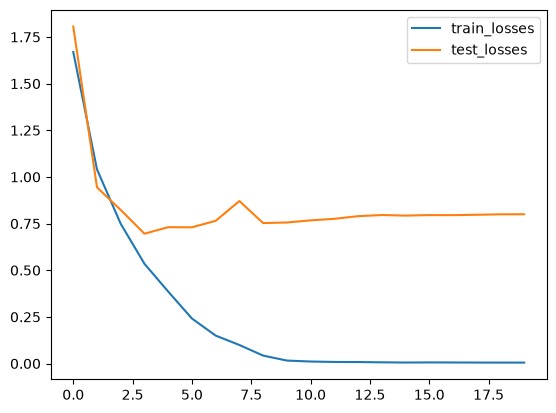

In [9]:
plt.plot(train_losses, label='train_losses')
plt.plot(test_losses, label='test_losses')
plt.legend()

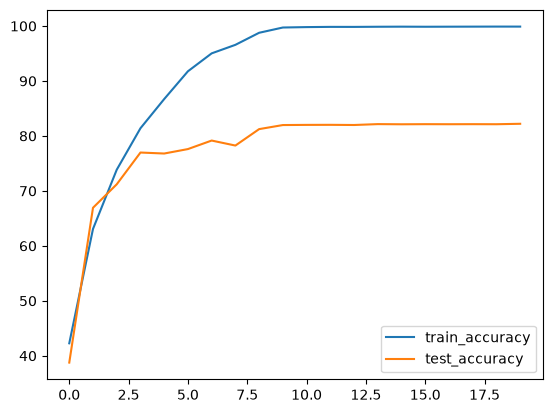

In [10]:
plt.plot(train_accuracies, label='train_accuracy')
plt.plot(test_accuracies, label='test_accuracy')
plt.legend()